# load data

In [1]:
import pandas as pd

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").iloc[:, 0]
y_test = pd.read_csv("../data/processed/y_test.csv").iloc[:, 0]

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (1600, 17)
Test shape: (400, 17)


# train baseline model

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.77

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.78      0.80       132
           1       0.65      0.68      0.66       132
           2       0.84      0.85      0.84       136

    accuracy                           0.77       400
   macro avg       0.77      0.77      0.77       400
weighted avg       0.77      0.77      0.77       400



# compare models

In [3]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

records = []
for name, clf in models.items():
    res = cross_validate(clf, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
    records.append({
        "Model": name,
        "Train Acc": f"{res['train_accuracy'].mean():.3f}",
        "CV Acc (Mean ± Std)": f"{res['test_accuracy'].mean():.3f} ± {res['test_accuracy'].std():.3f}",
        "Macro F1": f"{res['test_f1_macro'].mean():.3f}",
        "Overfit Gap": f"{(res['train_accuracy'].mean() - res['test_accuracy'].mean()):.3f}",
        "Folds": [round(s, 2) for s in res['test_accuracy']]
    })

pd.DataFrame(records)


,Model,Train Acc,CV Acc (Mean ± Std),Macro F1,Overfit Gap,Folds
0,Logistic Regression,0.768,0.756 ± 0.019,0.755,0.012,"[0.77, 0.78, 0.72, 0.76, 0.75]"
1,Random Forest,1.000,0.681 ± 0.028,0.677,0.319,"[0.72, 0.68, 0.68, 0.63, 0.7]"
2,Gradient Boosting,0.923,0.697 ± 0.014,0.694,0.226,"[0.7, 0.72, 0.68, 0.69, 0.69]"


# confusion matrix

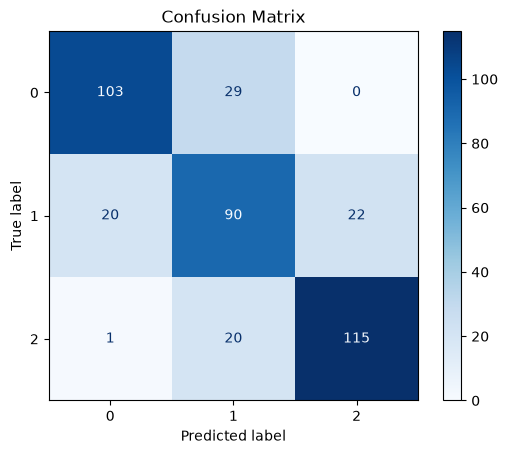

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# feature importance

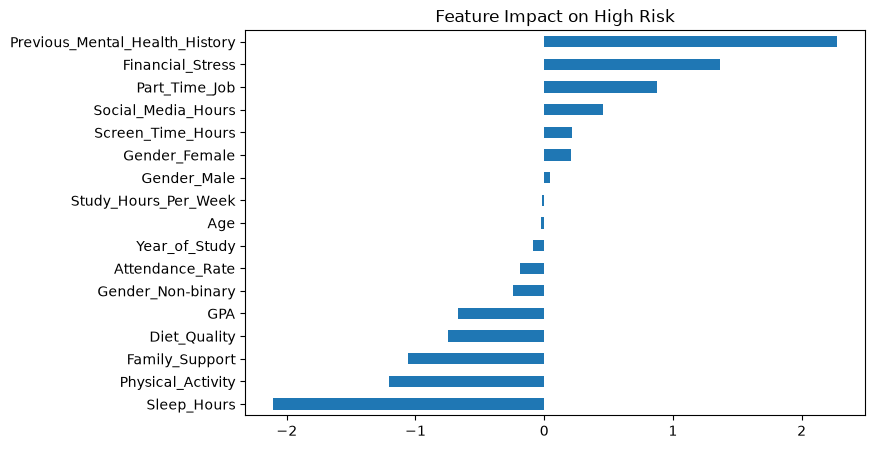

In [5]:
importance = pd.Series(model.coef_[2], index=X_train.columns).sort_values()

importance.plot(kind="barh", figsize=(8, 5))
plt.title("Feature Impact on High Risk")
plt.show()

# save model

In [6]:
import joblib

joblib.dump(model, "../models/best_model.joblib")
print("Model saved successfully!")

Model saved successfully!
